MLP (2 layers) d=128 run 3/3: 100%|██████████| 3000/3000 [00:01<00:00, 2052.52it/s, loss=0.03540]


saved results\test7_mnist.png
saved results\test7_mnist.pdf


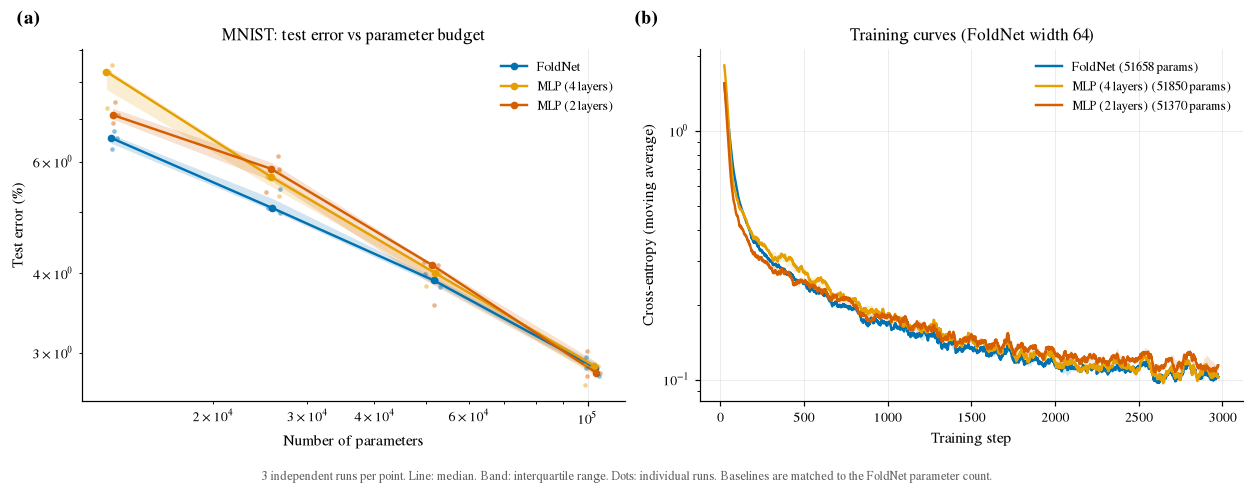

| FoldNet width | Model | Params | Test accuracy (%) | Test cross-entropy | Train time (s) | P(FoldNet better) | p-value |
|---|---|---|---|---|---|---|---|
| 16 | FoldNet | 12922 | **93.46 [93.38, 93.59]** | 0.228 [0.228, 0.230] | 1.5 | - | - |
|  | MLP (4 layers) | 12655 | 91.68 [91.59, 92.20] | 0.283 [0.270, 0.286] | 1.6 | 1.00 | n/a |
|  | MLP (2 layers) | 13002 | 92.89 [92.72, 93.00] | 0.254 [0.246, 0.256] | 1.1 | 1.00 | n/a |
| 32 | FoldNet | 25834 | **94.93 [94.75, 94.98]** | 0.173 [0.169, 0.176] | 1.5 | - | - |
|  | MLP (4 layers) | 25675 | 94.32 [94.25, 94.52] | 0.197 [0.188, 0.198] | 1.5 | 0.89 | n/a |
|  | MLP (2 layers) | 25647 | 94.15 [94.01, 94.39] | 0.201 [0.188, 0.203] | 1.2 | 0.89 | n/a |
| 64 | FoldNet | 51658 | **96.10 [96.05, 96.14]** | 0.128 [0.126, 0.130] | 1.6 | - | - |
|  | MLP (4 layers) | 51850 | 95.99 [95.99, 96.08] | 0.134 [0.131, 0.135] | 1.6 | 0.78 | n/a |
|  | MLP (2 layers) | 51370 | 95.88 [95.85, 96.16] | 0.130 [0.128, 0.133] | 1.3 | 0.67 | n/a |
| 128 

In [1]:
"""Test 7: MNIST classification. Accuracy-vs-budget sweep, FoldNet vs parameter-matched MLPs."""
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torchvision import datasets

from foldnet_lib import FoldNetClassifier, MLPClassifier, n_params, train_with_loader, DEV
from foldnet_bench import match_budget, seed_all
import foldnet_viz as V

WIDTHS = [16, 32, 64, 128]      # FoldNet widths; the baselines are matched to its parameter count
D_SHOW = 64                      # budget used for the training-curve panel
N_RUNS = 3
STEPS = 3000
BATCH = 128
NAMES = ["FoldNet", "MLP (4 layers)", "MLP (2 layers)"]
RESULTS_DIR = "results"
V.COLORS.setdefault("MLP (4 layers)", "#E69F00")
V.COLORS.setdefault("MLP (2 layers)", "#D55E00")


def load_mnist(root="./data"):
    tr = datasets.MNIST(root, train=True, download=True)
    te = datasets.MNIST(root, train=False, download=True)
    Xtr = tr.data.float().div(255).view(-1, 784).to(DEV)
    Xte = te.data.float().div(255).view(-1, 784).to(DEV)
    return Xtr, tr.targets.to(DEV), Xte, te.targets.to(DEV)


@torch.no_grad()
def evaluate(model, X, y, bs=2000):
    model.eval()
    correct, nll = 0, 0.0
    for j in range(0, X.shape[0], bs):
        logits = model(X[j:j + bs])
        correct += (logits.argmax(1) == y[j:j + bs]).sum().item()
        nll += F.cross_entropy(logits, y[j:j + bs], reduction="sum").item()
    return correct / X.shape[0], nll / X.shape[0]


def builders_for(d):
    target = n_params(FoldNetClassifier(784, 10, d, 4, 2))
    return {
        "FoldNet":        lambda: FoldNetClassifier(784, 10, d, 4, 2),
        "MLP (4 layers)": lambda: match_budget(lambda w: MLPClassifier(784, 10, w, 4), target, 4, 1024),
        "MLP (2 layers)": lambda: match_budget(lambda w: MLPClassifier(784, 10, w, 2), target, 4, 1024),
    }


def smooth(a, k=50):
    return np.convolve(a, np.ones(k) / k, mode="valid")


if __name__ == "__main__":
    V.set_style()
    Xtr, ytr, Xte, yte = load_mnist()

    R = {(n, d): [] for n in NAMES for d in WIDTHS}
    for d in WIDTHS:
        for n, build in builders_for(d).items():
            for r in range(N_RUNS):
                seed_all(r)
                m = build()
                out = train_with_loader(m, Xtr, ytr, steps=STEPS, batch=BATCH, lr=1e-3,
                                        desc=f"{n} d={d} run {r + 1}/{N_RUNS}")
                acc_te, nll_te = evaluate(m, Xte, yte)
                R[(n, d)].append(dict(err=100 * (1 - acc_te), nll=nll_te, curve=out["losses"],
                                      time=out["time"], n=n_params(m)))

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
    ax = axes[0]
    for n in NAMES:
        E = np.array([[r["err"] for r in R[(n, d)]] for d in WIDTHS]).T       # (runs, budgets)
        P = np.array([np.median([r["n"] for r in R[(n, d)]]) for d in WIDTHS])
        V.band(ax, P, E, V.color_for(n), label=n, marker="o")
        V.scatter_runs(ax, P, E, V.color_for(n))
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Number of parameters")
    ax.set_ylabel("Test error (%)")
    ax.set_title("MNIST: test error vs parameter budget")
    ax.legend()
    V.panel_label(ax, "(a)")

    ax = axes[1]
    for n in NAMES:
        S = np.stack([smooth(r["curve"]) for r in R[(n, D_SHOW)]])
        V.band(ax, np.arange(S.shape[1]) + 25, S, V.color_for(n),
               label=f"{n} ({int(np.median([r['n'] for r in R[(n, D_SHOW)]]))} params)")
    ax.set_yscale("log")
    ax.set_xlabel("Training step")
    ax.set_ylabel("Cross-entropy (moving average)")
    ax.set_title(f"Training curves (FoldNet width {D_SHOW})")
    ax.legend()
    V.panel_label(ax, "(b)")

    fig.text(0.5, -0.03, f"{N_RUNS} independent runs per point. Line: median. Band: interquartile "
             "range. Dots: individual runs. Baselines are matched to the FoldNet parameter count.",
             ha="center", fontsize=8, color="0.35")
    plt.tight_layout()
    V.savefig(fig, "test7_mnist", RESULTS_DIR)
    plt.show()

    tab = V.Table(["FoldNet width", "Model", "Params", "Test accuracy (%)", "Test cross-entropy",
                   "Train time (s)", "P(FoldNet better)", "p-value"])
    for d in WIDTHS:
        errs = {n: np.array([r["err"] for r in R[(n, d)]]) for n in NAMES}
        best = min(NAMES, key=lambda n: np.median(errs[n]))
        for n in NAMES:
            rr = R[(n, d)]
            pb, pv = ("-", "-") if n == "FoldNet" else V.vs_ref(errs["FoldNet"], errs[n])
            tab.add(d if n == NAMES[0] else "", n, int(np.median([r["n"] for r in rr])),
                    V.med_iqr(100 - errs[n], lambda v: f"{v:.2f}"),
                    V.med_iqr([r["nll"] for r in rr], lambda v: f"{v:.3f}"),
                    f"{np.median([r['time'] for r in rr]):.1f}", pb, pv,
                    bold={3} if n == best else ())
    tab.show()
    tab.save("test7_mnist_table", RESULTS_DIR,
             caption=(f"MNIST test accuracy over {N_RUNS} runs, median [Q1, Q3]. P(FoldNet better) "
                      "is computed on the test error. Bold: best median."),
             label="tab:mnist")